# Chile: RAN 21-13 Annex 1 on a CLP and UF balance sheet

**Question:** what interest rate risk does the Chilean regulator's Annex 1 assign to a bank with a balance sheet in pesos and UF, which shock decides its delta EVE and its delta NII, how much do the 50 percent offset and the indexation charge change them, and does the bank cross a line that makes it prioritised for supervision?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 05 of this topic
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- explain why the Chilean regulator treats the UF as a currency of its own (the UR) with its own curve, shock sizes, floor and charge, and read the two legs of a CLP and UF balance sheet;
- rebuild the curves of the two legs from the observed yields with the engine, and say what the peso curve lacks;
- compute the delta EVE of each leg under the six shocks, combine the two legs with the 50 percent offset rule, and obtain the Annex 1 delta EVE;
- compute the delta NII of each leg, add the indexation charge, and obtain the Annex 1 delta NII;
- apply the three tests that make a bank prioritised, and read the distance of every post-shock rate to its floor.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import curves, eve_nii, shocks, slotting

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

The data is case C15: **Banco Andino**, a **synthetic** bank with a balance sheet in Chilean pesos (CLP) and in UF (the Chilean inflation-indexed unit of account, CLF), at the valuation date 2026-09-03. Its aggregates are calibrated to the system figures of the CMF's August 2026 report (https://www.cmfchile.cl/portal/estadisticas/617/articles-113863_recurso_1.pdf, the Chilean regulator, public statistics of the licence class `mirror-allowed`); the UF share, the repricing profile of each item, the deposit split and every behavioural assumption are synthetic and stated in the document. The **curves are real**: the yields of the Banco Central de Chile (BDE table F022, `mirror-allowed`, attribution "Fuente: Banco Central de Chile, Base de Datos Estadísticos") and the value of the UF of the date (series F073.UFF.PRE.Z.D). Money is in CLP millions; the UF leg is in CLF millions and is converted with the UF value only where the two legs are added. The engine never converts between currencies.

The case commits six variants of the same bank, each a different stress on the book: `short-uf` (net short in UF at 30 percent of Tier 1), `long-uf` (net long), `cpi-surprise` (net long, with an inflation surprise of 2.5 points), `clp-steepener` (a longer peso book), `offset-on-off` (the offset rule compared with and without) and `floors-active` (70 percent of the UF commercial loans floating, to bring the floors into play).

- **Files read:** `data/derived/C15/short-uf.json`, `long-uf.json`, `cpi-surprise.json`, `clp-steepener.json`, `offset-on-off.json` and `floors-active.json` (`outputs.legs`, `curves`, `eve`, `nii`, `floors`, `offset_rule`, `indexation_charge`, `cpi_scenario`, `thresholds`) and `models-banco-andino-2026-09.json` (`fit.annex1_table`, `multipliers`, `nmd_caps`, `buckets`).

The next cell loads the seven files and prints the notice of the bank and the names of the variants.

In [2]:
# Load the six variants and the model document (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C15"
ids = ["short-uf", "long-uf", "cpi-surprise", "clp-steepener", "offset-on-off", "floors-active"]
variants = {v: json.loads((derived / f"{v}.json").read_text(encoding="utf-8")) for v in ids}
fit = json.loads((derived / "models-banco-andino-2026-09.json").read_text(encoding="utf-8"))["fit"]
out = variants["short-uf"]["outputs"]
MID = slotting.bucket_grid().midpoints
LANG = "en"  # the bilingual fields of the documents are read in this language
NAME = {"parallel-up": "parallel up", "parallel-down": "parallel down", "steepener": "steepener"}
NAME.update({"flattener": "flattener", "short-up": "short up", "short-down": "short down"})
NAME.update({"delta-eve": "delta EVE", "delta-nii": "delta NII", "on": "on", "off": "off"})
NAME.update({"compared": "compared", True: "yes", False: "no"})
print(out["bank"]["notice"][LANG])
print("variants:", ids)

Banco Andino is a synthetic bank. Its balance-sheet aggregates are calibrated to the CMF system aggregates of August 2026; the UF share, the repricing profile of each item, the deposit split and every behavioural assumption are synthetic and stated in the document. The curves are real: the Banco Central de Chile F022 yields of the valuation date.
variants: ['short-uf', 'long-uf', 'cpi-surprise', 'clp-steepener', 'offset-on-off', 'floors-active']


## Method

Annex 1 of chapter 21-13 of the Recopilacion Actualizada de Normas of the CMF (https://www.cmfchile.cl/portal/principal/623/articles-29808_doc_pdf.pdf; dossier 03, F.2) defines two standard measures of the interest rate risk of the banking book, both by significant currency: the **delta NII** (a constant balance sheet, the repricing flows up to one year) and the **delta EVE** (a run-off balance sheet, all repricing flows). It is built on the Basel standard (SRP31), with the Chilean particularities that this notebook walks through: the UF as a currency of its own, a table of shock sizes of its own, a floor of its own, an indexation charge, an offset rule between the peso and the UF, and three tests that make a bank "prioritised" for supervision.

### Step 1: the UF as one currency, the UR

Chilean loans and deposits are often indexed to the UF, a unit whose value in pesos follows inflation. Annex 1 says that "the flows in indexed local currency are treated as a single currency, which we will call UR" (CLF, the UF-indexed peso). The risk of that currency is not only the real rate: the **indexation (reajustabilidad) risk** is the exposure to losses from adverse changes in the indexation units. The notebook therefore keeps two legs. The CLP leg holds the nominal peso flows in CLP millions; the UR leg holds the UF flows in CLF millions. The **net UF position** $PN_{UR}$ is the difference between the UF assets and liabilities, converted to pesos with the UF value of the date. The next cell prints the two legs and recomputes $PN_{UR}$.

All CLP-indexed (UF) flows are treated as one currency, UR (RAN 21-13 Annex 1).
UF value on 2026-09-03 : 40877.73 CLP
        items           assets      liabilities     net position
CLP        12     4,988,540.25     3,917,062.27     1,071,477.98  CLP
UR          5            65.89            71.94            -6.05  CLF
PN_UR = -247264.15 CLP millions
net UF position over Tier 1: -0.3


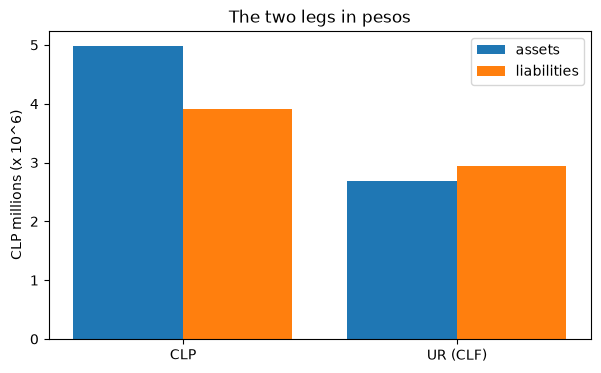

In [3]:
# The two legs of the bank in their own units, the net UF position in pesos and the legs in pesos
uf = out["ur_currency"]["uf_value"]
print(out["ur_currency"]["definition"][LANG])
print("UF value on", out["ur_currency"]["uf_date"], ":", uf, "CLP")
print(f"{'':4s} {'items':>8s} {'assets':>16s} {'liabilities':>16s} {'net position':>16s}")
for leg in out["legs"]:
    totals = (leg["assets_total"], leg["liabilities_total"], leg["net_position"])
    cells = " ".join(f"{t:16,.2f}" for t in totals)
    print(f"{leg['leg']:4s} {len(leg['items']):8d} {cells}  {leg['currency']}")
pn_ur = out["legs"][1]["net_position"] * uf
print("PN_UR =", round(pn_ur, 2), "CLP millions")
print("net UF position over Tier 1:", round(pn_ur / out["thresholds"]["tier1"], 4))
fig, ax = plt.subplots(figsize=(7, 4))
for j, leg in enumerate(out["legs"]):
    factor = uf if leg["currency"] == "CLF" else 1.0
    a_tot, l_tot = leg["assets_total"] * factor / 1e6, leg["liabilities_total"] * factor / 1e6
    ax.bar(j - 0.2, a_tot, 0.4, color="tab:blue", label="assets" if j == 0 else None)
    ax.bar(j + 0.2, l_tot, 0.4, color="tab:orange", label="liabilities" if j == 0 else None)
ax.set_xticks([0, 1], ["CLP", "UR (CLF)"])
ax.set_ylabel("CLP millions (x 10^6)")
ax.set_title("The two legs in pesos")
ax.legend()
plt.show()

The peso leg is the whole balance sheet in size: assets of about 5.0 trillion pesos against liabilities of 3.9 trillion. The UF leg looks tiny, 65.89 and 71.94 million CLF, but each UF is worth 40,877.73 pesos, so once converted it is a leg of about 2.7 and 2.9 trillion pesos, and its net position of -6.05 million CLF is -247,264 CLP millions, the -0.3 of Tier 1 that the variant is built to have. The two legs are not comparable in their own units, which is why the engine never converts and the notebook converts only here and where the legs are added. What the picture does not show is the timing of each leg, which is what the curves and the 19 bands carry.

### Step 2: the two curves

Each leg is discounted on its own curve. The notebook rebuilds both from the observed yields in the document with the engine, in the same three steps as notebook 01: `bootstrap_zero_curve` turns the par yields into continuously compounded zero rates, `fit_nelson_siegel` fits a smooth curve to them, and `nelson_siegel_yield` evaluates it at the 19 midpoints. The UF curve has four published tenors (2, 5, 10 and 30 years). The peso curve has only three (2, 5 and 10 years) and the Nelson-Siegel fit of the engine needs four points, so the pipeline adds the monetary policy rate of the Banco Central, the overnight rate, as the fourth point at 1/360 year. It is a **policy rate and not a secondary-market yield**, a choice of Contraste that the document states as an open question. The next cell rebuilds both curves, prints their parameters and the curves at some bands, and draws them.

CLP: tenors (years) [2.8e-03 2.0e+00 5.0e+00 1.0e+01]
    Nelson-Siegel β0 0.06045 β1 -0.01546 β2 -0.01807 τ 1.00
    error (bp) 0.500
UR: tenors (years) [ 2.  5. 10. 30.]
    Nelson-Siegel β0 0.03029 β1 -0.01825 β2 -0.00080 τ 2.50
    error (bp) 0.412
band  1 |   0.0028 | CLP 0.04499 | UR 0.01205
band  6 |   0.8750 | CLP 0.04564 | UR 0.01478
band 10 |   3.5000 | CLP 0.05171 | UR 0.02024
band 15 |   8.5000 | CLP 0.05651 | UR 0.02490
band 19 |  25.0000 | CLP 0.05911 | UR 0.02839


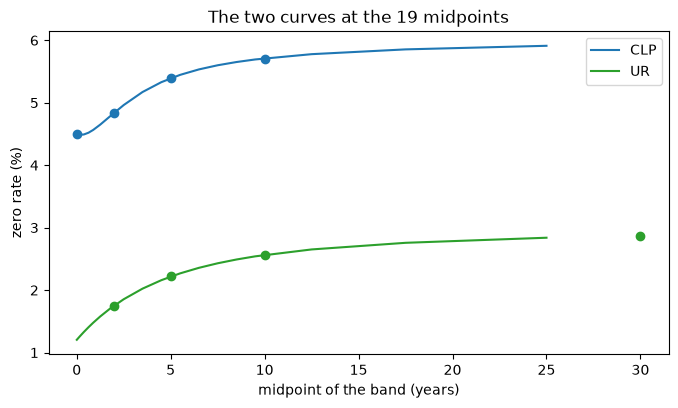

In [4]:
# Rebuild both curves from the observed yields: bootstrap, Nelson-Siegel fit and values at the 19 midpoints
r0, observed = {}, {}
for leg, key in (("CLP", "clp"), ("UR", "ur")):
    block = out["curves"][key]
    tenors = np.array([p["tenor_years"] for p in block["points"]])
    par = np.array([p["observed_yield"] for p in block["points"]])
    zero = curves.bootstrap_zero_curve(tenors, par, 2)
    ns = curves.fit_nelson_siegel(tenors, zero)
    r0[leg] = curves.nelson_siegel_yield(MID, ns.beta0, ns.beta1, ns.beta2, ns.tau)
    observed[leg] = (tenors, zero)
    print(f"{leg}: tenors (years) {np.round(tenors, 4)}")
    print(f"    Nelson-Siegel β0 {ns.beta0:.5f} β1 {ns.beta1:.5f} β2 {ns.beta2:.5f} τ {ns.tau:.2f}")
    print(f"    error (bp) {ns.rmse * 1e4:.3f}")
for k in (0, 5, 9, 14, 18):
    print(f"band {k + 1:2d} | {MID[k]:8.4f} | CLP {r0['CLP'][k]:.5f} | UR {r0['UR'][k]:.5f}")
fig, ax = plt.subplots(figsize=(8, 4.2))
for leg, colour in (("CLP", "tab:blue"), ("UR", "tab:green")):
    ax.plot(MID, r0[leg] * 100, color=colour, label=leg)
    ax.plot(observed[leg][0], observed[leg][1] * 100, "o", color=colour)
ax.set_xlabel("midpoint of the band (years)")
ax.set_ylabel("zero rate (%)")
ax.set_title("The two curves at the 19 midpoints")
ax.legend()
plt.show()

The lines are the Nelson-Siegel curves at the 19 midpoints and the dots the observed zero rates they were fitted to. The peso curve sits near 4.5 percent at the shortest band and rises to about 5.9 percent at 25 years; the UF curve, a real rate, starts at 1.2 percent and ends near 2.8, so the nominal curve is about three points above the real one, the inflation compensation the market prices. The peso fit has only three market yields and the policy rate as its first point, so its shortest end is a policy rate and not a market yield, an open choice the document states and a validator should read as a limit. The fits are tight, 0.50 and 0.41 bp, but a tight fit on four points is not much evidence.

### Step 3: the bands, the deposit caps and the multipliers

The 19 bands and their midpoints are those of the Basel standard (notebook 01, step 1); the Annex repeats the midpoints. The caps on non-maturity deposits are the Basel ones (SRP31, Table 4) under the Chilean names: retail with an operational relationship (90 percent, 5 years), retail without (70 percent, 4.5 years) and wholesale (50 percent, 4 years); the engine accepts both names (`retail-operational` is `retail-transactional`). The Annex also repeats the multipliers by shock of the prepayment rate and of the early redemption of term deposits (SRP31.119, SRP31.125). The next cell splits the three deposit segments of the bank with the engine and applies the multipliers to the bank's own base rates, and draws both.

retail-operational       request 0.95/5.5 y
    -> 0.90/5.0 y | cap applied yes
retail-non-operational   request 0.70/4.0 y
    -> 0.70/4.0 y | cap applied no
wholesale                request 0.60/4.5 y
    -> 0.50/4.0 y | cap applied yes
base rates: CPR 0.05 | TDRR 0.05
parallel up            CPR 0.0400 | TDRR 0.0600
parallel down          CPR 0.0600 | TDRR 0.0400
steepener              CPR 0.0400 | TDRR 0.0400
flattener              CPR 0.0600 | TDRR 0.0600
short up               CPR 0.0400 | TDRR 0.0600
short down             CPR 0.0600 | TDRR 0.0400


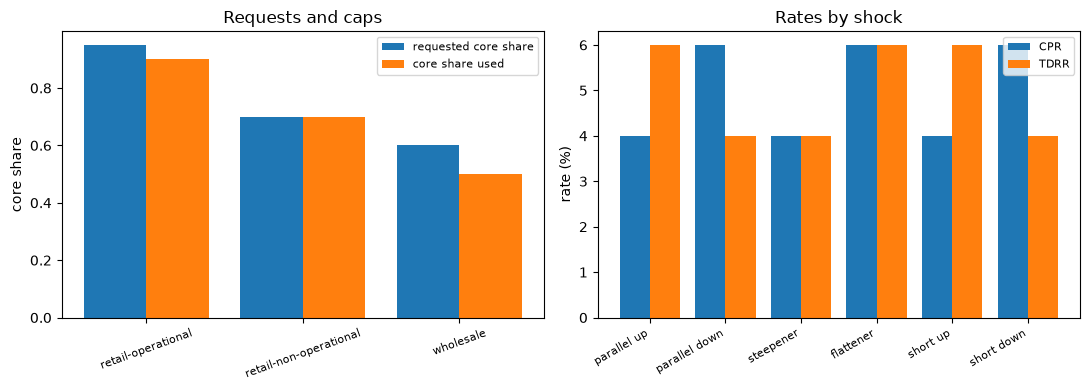

In [5]:
# Split the three deposit segments with the engine's caps and scale the bank's base rates by shock
asked, used = [], []
for seg in out["nmd_segments"]:
    args = (seg["balance"], seg["category"], seg["requested_core_share"], seg["requested_core_maturity_years"])
    r = slotting.nmd_split(*args)
    asked.append(seg["requested_core_share"])
    used.append(r.core_share_used)
    print(f"{seg['category']:24s} request {asked[-1]:.2f}/{seg['requested_core_maturity_years']:.1f} y")
    print(f"    -> {r.core_share_used:.2f}/{r.core_maturity_used_years:.1f} y | cap applied {NAME[r.cap_applied]}")
cpr0 = out["assumptions"]["prepayment_cpr"]["value"]
tdrr0 = out["assumptions"]["term_deposit_redemption_rate"]["value"]
print(f"base rates: CPR {cpr0:.2f} | TDRR {tdrr0:.2f}")
cpr_s = [slotting.prepayment_cpr(s, cpr0) for s in shocks.SHOCKS]
tdrr_s = [slotting.term_deposit_redemption_rate(s, tdrr0) for s in shocks.SHOCKS]
for s, c, t in zip(shocks.SHOCKS, cpr_s, tdrr_s):
    print(f"{NAME[s]:22s} CPR {c:.4f} | TDRR {t:.4f}")
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
left.bar(np.arange(3) - 0.2, asked, 0.4, label="requested core share")
left.bar(np.arange(3) + 0.2, used, 0.4, label="core share used")
left.set_xticks(np.arange(3), [s["category"] for s in out["nmd_segments"]], rotation=20, fontsize=8)
left.set_ylabel("core share")
left.set_title("Requests and caps")
left.legend(fontsize=8)
right.bar(np.arange(6) - 0.2, np.array(cpr_s) * 100, 0.4, label="CPR")
right.bar(np.arange(6) + 0.2, np.array(tdrr_s) * 100, 0.4, label="TDRR")
right.set_xticks(np.arange(6), [NAME[s] for s in shocks.SHOCKS], rotation=30, ha="right", fontsize=8)
right.set_ylabel("rate (%)")
right.set_title("Rates by shock")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

On the left the retail operational segment asks for 95 percent core and is cut to 90, the wholesale one asks for 60 and is cut to 50, and the retail non-operational one asks for exactly its cap, 70, and is not cut: the bank's requests are sometimes above the standard and sometimes at it. On the right the multipliers bend the 5 percent base rates: prepayment falls to 4 percent under the parallel-up, steepener and short-up shocks and rises to 6 percent under the other three, and early redemption of term deposits moves the other way for the parallel-up, flattener and short-up shocks. The figure shows how the assumptions respond to a shock, not whether the base rates are right: they are synthetic.

### Step 4: the delta EVE of each leg

For each of the six shocks and each leg, the Annex discounts the base flows and the shocked flows and takes the difference, loss-positive (SRP31.129, repeated in the Annex, Hojas 10 to 12):

$$\Delta EVE_{i,c} = \sum_{k=1}^{19} CF_{0,c}(t_k)\, DF_{0,c}(t_k) - \sum_{k=1}^{19} CF_{i,c}(t_k)\, DF_{i,c}(t_k) + KAO_{i,c}, \qquad DF_{i,c}(t_k) = e^{-r_{i,c}(t_k)\, t_k}$$

where $c$ is the currency (CLP or UR), $i$ the shock and $KAO$ the add-on for automatic options (zero here). The shocked rate is the base rate plus the shape of notebook 02 with the sizes of the Chilean table (CLP 300, 400 and 200 bp; UR 200, 250 and 150 bp), floored at 0 percent for the peso and at -2 percent for the UR. The shocked flows are the base flows with the early redemption of term deposits moved to the overnight band at the multiplier rate of the shock; the document stores them as `net_cash_flows`. The next cell rebuilds the base flows from the items (the UR leg converted at the UF value, the engine never converting), shocks and floors the curves with `shock_curve` and `apply_floor`, and calls `delta_eve` for the six shocks and the two legs.

parallel up                34,216.3     45,427.0
parallel down             -39,940.6    -69,821.5
steepener                  -8,821.7     38,748.2
flattener                  16,210.5    -32,556.6
short up                   28,675.1     -3,889.5
short down                -26,245.2      5,720.7


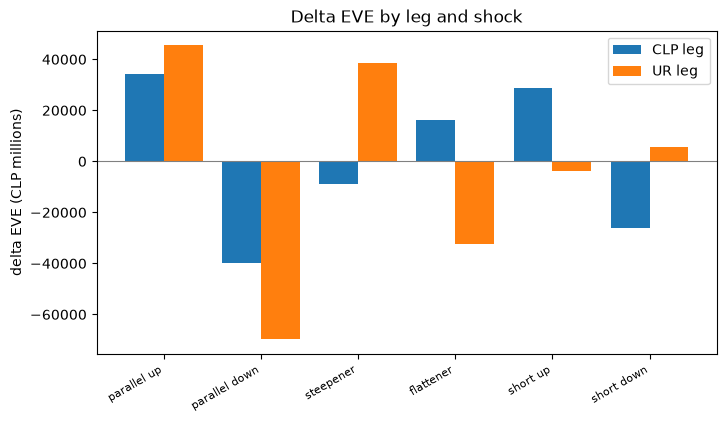

In [6]:
# Rebuild the base flows of each leg, shock and floor the curves, and call delta_eve for the six shocks
conv = {"CLP": 1.0, "UR": uf}
floors = {"CLP": out["floors"]["other_floor"], "UR": out["floors"]["ur_floor"]}
sizes = {"CLP": shocks.shock_size("CLP", "cmf-annex1"), "UR": shocks.shock_size("CLF", "cmf-annex1")}
base = {}
for leg in out["legs"]:
    rows = [r for item in leg["items"] for r in item["cash_flows"]]
    buckets, amounts = [r["bucket"] - 1 for r in rows], [r["amount"] for r in rows]
    base[leg["leg"]] = conv[leg["leg"]] * np.bincount(buckets, weights=amounts, minlength=19)
delta_eve = {"CLP": [], "UR": []}
for row in out["eve"]["rows"]:
    for leg, key in (("CLP", "clp"), ("UR", "ur")):
        z = sizes[leg]
        shape = shocks.shock_curve(row["shock"], z.parallel_bp, z.short_bp, z.long_bp, MID)
        shocked = shocks.apply_floor(r0[leg], shape, floors[leg])
        flows = np.array(row[key]["net_cash_flows"])
        delta_eve[leg].append(eve_nii.delta_eve(base[leg], flows, r0[leg], shocked, MID))
    print(f"{NAME[row['shock']]:22s} {delta_eve['CLP'][-1]:12,.1f} {delta_eve['UR'][-1]:12,.1f}")
x = np.arange(6)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(x - 0.2, delta_eve["CLP"], 0.4, label="CLP leg")
ax.bar(x + 0.2, delta_eve["UR"], 0.4, label="UR leg")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xticks(x, [NAME[s] for s in shocks.SHOCKS], rotation=30, ha="right", fontsize=8)
ax.set_ylabel("delta EVE (CLP millions)")
ax.set_title("Delta EVE by leg and shock")
ax.legend()
plt.show()

Read the bars shock by shock. The parallel-up shock loses for both legs, 34,216 for the pesos and 45,427 for the UR, so it is the shock that will decide the measure; the parallel-down shock gains for both. The steepener and the flattener split the legs, a loss for the UR and a gain for the pesos in the steepener and the reverse in the flattener, which is exactly where the offset rule will act in the next step. The picture shows the deltas of each leg alone: it says nothing yet about the Annex measure, which combines the legs. It also shows that the UR leg, a book of a few million UF, moves the EVE as much as the peso leg because it is longer.

### Step 5: the 50 percent offset and the Annex 1 delta EVE

A peso rate move and a UF rate move are partly independent, so the Annex does not simply add the losses of the two legs. When the peso and the UR deltas have **opposite signs**, half of the gain leg offsets the loss leg, with a floor at zero (Annex 1, Hojas 10 to 12; dossier 03, F.2):

$$\Delta_{CLP+CLF} = \begin{cases} \max(0.5\, \Delta_{CLP} + \Delta_{CLF},\ 0) & \text{if } \Delta_{CLP} \le 0 < \Delta_{CLF} \\ \max(\Delta_{CLP} + 0.5\, \Delta_{CLF},\ 0) & \text{if } \Delta_{CLF} \le 0 < \Delta_{CLP} \\ \max(\Delta_{CLP}, 0) + \max(\Delta_{CLF}, 0) & \text{otherwise} \end{cases}$$

The 50 percent applies to the gain leg only. The Annex delta EVE is the maximum over the six shocks of the pair, plus the positive part of any other significant currency (none here). The engine's `cmf_pair` is the pair and `annex1_delta_eve` the maximum. The first cell below shows the rule on eight pairs of illustrative numbers, with and without the offset; the second applies it to the bank.

  Δ CLP   Δ CLF        with offset       without offset
     10      20               30.0                 30.0
    -10     -20                0.0                  0.0
     30     -20               20.0                 30.0
    -20      30               20.0                 30.0
     10     -40                0.0                 10.0
    -40      10                0.0                 10.0
      0      25               25.0                 25.0
     25       0               25.0                 25.0


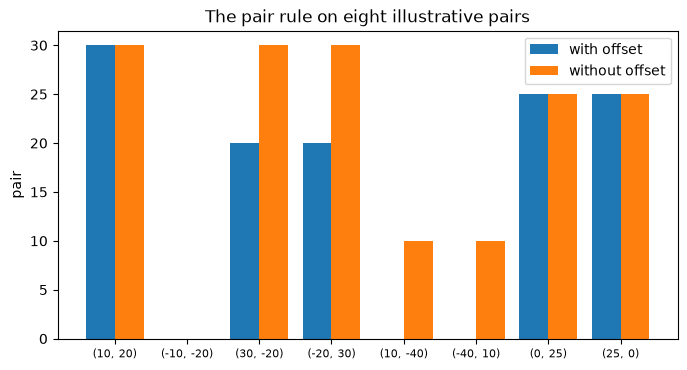

In [7]:
# The offset rule on eight illustrative pairs, with and without the offset
cases = ((10, 20), (-10, -20), (30, -20), (-20, 30), (10, -40), (-40, 10), (0, 25), (25, 0))
with_off = [eve_nii.cmf_pair(clp, clf, True) for clp, clf in cases]
without = [eve_nii.cmf_pair(clp, clf, False) for clp, clf in cases]
print(f"{'Δ CLP':>7s} {'Δ CLF':>7s} {'with offset':>18s} {'without offset':>20s}")
for (clp, clf), a, b in zip(cases, with_off, without):
    print(f"{clp:7d} {clf:7d} {a:18.1f} {b:20.1f}")
x = np.arange(len(cases))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - 0.2, with_off, 0.4, label="with offset")
ax.bar(x + 0.2, without, 0.4, label="without offset")
ax.set_xticks(x, [f"({clp}, {clf})" for clp, clf in cases], fontsize=8)
ax.set_ylabel("pair")
ax.set_title("The pair rule on eight illustrative pairs")
ax.legend()
plt.show()

The two bars differ only where the signs of the two legs are opposite. For (30, -20) the loss leg pays 30 and the gain leg of 20 offsets half of itself, 10, so the pair is 20 with the offset and 30 without; for (10, -40) the half of 40 is 20, more than the loss of 10, so the pair is floored at zero. When both legs lose, (10, 20) or (0, 25), or both gain, (-10, -20), the offset does nothing. These are illustrative numbers and not the bank, chosen to show the four regimes of the rule: the figure is the rule, not a finding.

Now the bank. The next cell applies the pair rule to the six pairs of leg deltas of Step 4 and takes the maximum, with the offset the variant uses and, for comparison, without it.

parallel up                  79,643.4       79,643.4
parallel down                     0.0            0.0
steepener                    34,337.4       38,748.2
flattener                         0.0       16,210.5
short up                     26,730.3       28,675.1
short down                        0.0        5,720.7
Annex 1 delta EVE 79,643.4 (worst shock: parallel up)
offset state of this variant: on
share of the gain leg that offsets: 0.5
delta EVE as a share of Tier 1: 0.0966


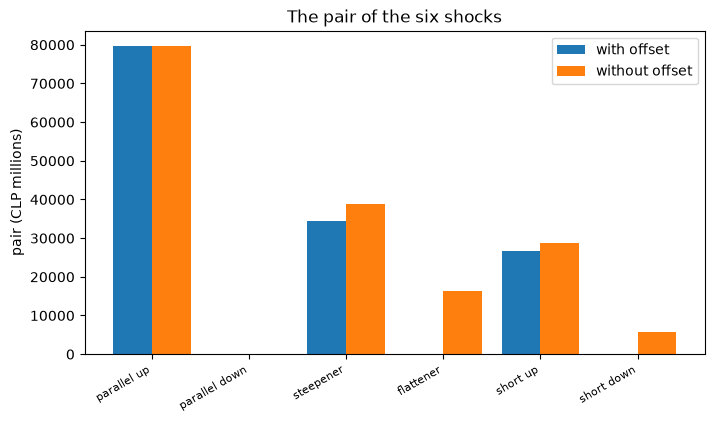

In [8]:
# Apply the pair rule and the maximum to the bank's six shocks, with and without the offset
offset = out["offset_rule"]["state"] != "off"
d_clp, d_ur = np.array(delta_eve["CLP"]), np.array(delta_eve["UR"])
a1 = eve_nii.annex1_delta_eve(d_clp, d_ur, offset)
no_offset = eve_nii.annex1_delta_eve(d_clp, d_ur, False)
for k, s in enumerate(shocks.SHOCKS):
    print(f"{NAME[s]:22s} {a1.pairs[k]:14,.1f} {no_offset.pairs[k]:14,.1f}")
print(f"Annex 1 delta EVE {a1.delta_eve:,.1f} (worst shock: {NAME[a1.worst_shock]})")
print("offset state of this variant:", NAME[out["offset_rule"]["state"]])
print("share of the gain leg that offsets:", out["offset_rule"]["share"])
print("delta EVE as a share of Tier 1:", round(a1.delta_eve / out["thresholds"]["tier1"], 4))
x = np.arange(6)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.bar(x - 0.2, a1.pairs, 0.4, label="with offset")
ax.bar(x + 0.2, no_offset.pairs, 0.4, label="without offset")
ax.set_xticks(x, [NAME[s] for s in shocks.SHOCKS], rotation=30, ha="right", fontsize=8)
ax.set_ylabel("pair (CLP millions)")
ax.set_title("The pair of the six shocks")
ax.legend()
plt.show()

For the bank the offset acts in the two rotations and the short shocks: the steepener pair is 34,337 with the offset and 38,748 without, the flattener is 0 with it and 16,211 without, and the parallel-down shock is 0 either way because both legs gain. The worst shock is the parallel-up one at 79,643, the sum of the two losses, where the offset does nothing, so the Annex measure is the same with and without it. That is the general point: the offset changes the measure only when it changes the worst shock, and for this bank it does not. The delta EVE is 9.66 percent of Tier 1, under the 15 percent line, which the last steps test.

### Step 6: the delta NII and the indexation charge

The delta NII uses a **single parallel shock of 300 bp for both legs**, up and down, on the flows of the first year, weighted by the time left in the year, loss-positive (Annex 1, Hoja 10; dossier 03, F.2):

$$\Delta NII_{i,c} = \sum_{t_k < 1} CF_c(t_k)\, \big(r_{0,c}(t_k) - r_{i,c}(t_k)\big)\, (1 - t_k)$$

The two legs are paired with the same offset rule, the maximum over the two shocks is taken, and the **indexation charge** is added once, after the maximum:

$$\Delta NII = \max_{i \in \{up,\ down\}} \Delta NII_{i,(CLP+CLF)} + 2.5\% \cdot |PN_{UR}|$$

The charge is "the standardised indexation (reajustabilidad) charge", an implied 2.5 percent inflation surprise on the absolute net UF position. The engine's `delta_nii` is the leg, `indexation_charge` the charge and `annex1_delta_nii` the whole. The next cell recomputes the six figures of the two shocks and the two legs, and then the Annex measure.

parallel up      shock +300 bp | ΔNII CLP   -7,059.4
    ΔNII UR    8,414.9
parallel down    shock -300 bp | ΔNII CLP    7,059.4
    ΔNII UR   -8,414.9
pairs (up, down) [4885.3 2851.9] | maximum pair 4,885.3 (parallel up)
charge 6,181.6 | ΔNII 11,066.9
the charge as a share of the delta NII: 0.5586


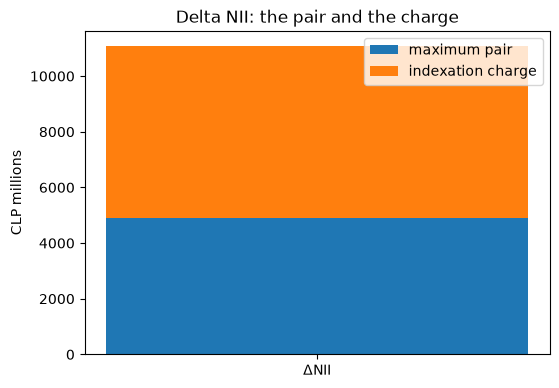

In [9]:
# Recompute the delta NII of each leg for +300 and -300 bp, pair the legs and add the indexation charge
delta_nii = {"CLP": [], "UR": []}
for row in out["nii"]["rows"]:
    bp = row["clp"]["shock_bp"]
    for leg in ("CLP", "UR"):
        shocked = shocks.apply_floor(r0[leg], np.full(19, bp), floors[leg])
        delta_nii[leg].append(eve_nii.delta_nii(base[leg], r0[leg], shocked, MID))
    print(f"{NAME[row['shock']]:16s} shock {bp:+.0f} bp | ΔNII CLP {delta_nii['CLP'][-1]:10,.1f}")
    print(f"    ΔNII UR {delta_nii['UR'][-1]:10,.1f}")
a2 = eve_nii.annex1_delta_nii(np.array(delta_nii["CLP"]), np.array(delta_nii["UR"]), pn_ur, offset)
print(f"pairs (up, down) {np.round(a2.pairs, 1)} | maximum pair {a2.max_pair:,.1f} ({NAME[a2.worst_shock]})")
print(f"charge {a2.indexation_charge:,.1f} | ΔNII {a2.delta_nii:,.1f}")
print("the charge as a share of the delta NII:", round(a2.indexation_charge / a2.delta_nii, 4))
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.bar(["ΔNII"], [a2.max_pair], label="maximum pair")
ax.bar(["ΔNII"], [a2.indexation_charge], bottom=[a2.max_pair], label="indexation charge")
ax.set_ylabel("CLP millions")
ax.set_title("Delta NII: the pair and the charge")
ax.legend()
plt.show()

The single bar is the Annex delta NII built in two blocks: the maximum pair of the two 300 bp shocks, 4,885 with the offset, and the indexation charge, 6,182, added once after the maximum. More than half of the measure, 55.9 percent, is the charge, which does not depend on the shock or on the legs' deltas but on the size of the net UF position. The pesos gain when rates rise (-7,059) and the UR loses (8,415), so the pair with the offset is 4,885 against 8,415 without it. The picture shows the composition of the measure; it does not show that a charge of this size is a good estimate of inflation risk, only that the Annex sets it so.

A detail of the code of the previous cell worth reading: the legs of the first shock have opposite signs (the peso loses when the rate falls and the UF when it rises, or the reverse), so the offset rule bites in the NII too. The charge, in contrast, does not depend on the shock or on the legs' deltas: it depends on the size of the net UF position and on nothing else, and it is positive whatever the sign of the position. The CPI-surprise variant makes the difference concrete. A net long UF position gains from inflation, yet it pays the same charge as a net short one. The next cell prints the charge and the CPI scenario of the long and of the short variants.

short-uf      PN_UR   -247,264.2 | charge (engine)   6,181.6
long-uf       PN_UR    247,264.2 | charge (engine)   6,181.6
cpi-surprise  PN_UR    247,264.2 | charge (engine)   6,181.6
    CPI surprise +2.5 pp | effect (loss positive) -6,181.6


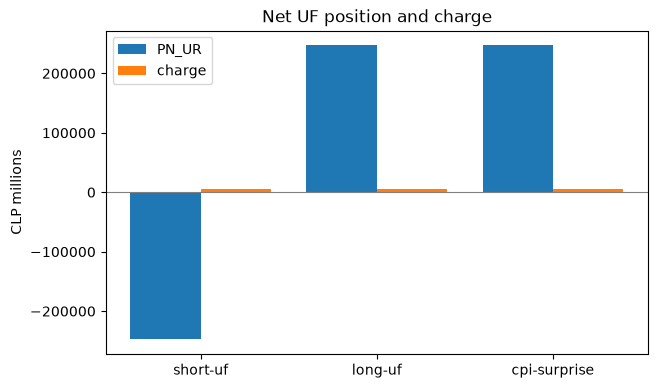

In [10]:
# The indexation charge with the engine for a net short and a net long UF position, and the CPI-surprise scenario
positions, charges = [], []
for v in ("short-uf", "long-uf", "cpi-surprise"):
    o = variants[v]["outputs"]
    position = o["legs"][1]["net_position"] * o["ur_currency"]["uf_value"]
    charge = eve_nii.indexation_charge(position)
    positions.append(position)
    charges.append(charge)
    print(f"{v:13s} PN_UR {position:12,.1f} | charge (engine) {charge:9,.1f}")
    cs = o["cpi_scenario"]
    if cs:
        print(f"    CPI surprise +{cs['surprise_pp']:.1f} pp | effect (loss positive) {cs['effect']:,.1f}")
x = np.arange(3)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.bar(x - 0.2, positions, 0.4, label="PN_UR")
ax.bar(x + 0.2, charges, 0.4, label="charge")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xticks(x, ["short-uf", "long-uf", "cpi-surprise"])
ax.set_ylabel("CLP millions")
ax.set_title("Net UF position and charge")
ax.legend()
plt.show()

The position bars are mirror images, -247,264 for the short bank and +247,264 for the long ones, and the charge bars are the same height, 6,182, for all three: the charge is one-sided and depends on the absolute position. The CPI scenario, in contrast, is two-sided: a 2.5 point inflation surprise is a loss of 6,182 for a short position and a gain, an effect of -6,182 in the loss-positive convention, for a long one. The standard charge is therefore an add-on that a net long bank pays although it gains from the surprise; the scenario shows what the same inflation move does to each bank. The picture is one pair of banks and one surprise; it does not describe the distribution of inflation.

### Step 7: the prioritised-bank tests

The Annex makes a bank **prioritised** for the supervisor's detailed review if any of three ratios is strictly above its line: the delta NII over Tier 1 above 5 percent, the delta EVE over Tier 1 above 15 percent, or the delta NII over the 12-month cumulative net interest and indexation margin above 18 percent (dossier 03, F.2). The engine's `prioritised_bank` takes the two measures, the Tier 1 and the margin and returns the three tests. The Tier 1 and the margin are in the document (the margin is the base NII of the dynamic projection of the two legs, in the same units). The next cell applies it to the figures just recomputed.

Tier 1: 824213.8
12-month margin: 274664.5
nii-tier1  measure    11,066.9 /   824,213.8 = 0.0134
    line 0.05 | no
eve-tier1  measure    79,643.4 /   824,213.8 = 0.0966
    line 0.15 | no
nii-margin measure    11,066.9 /   274,664.5 = 0.0403
    line 0.18 | no
prioritised: no


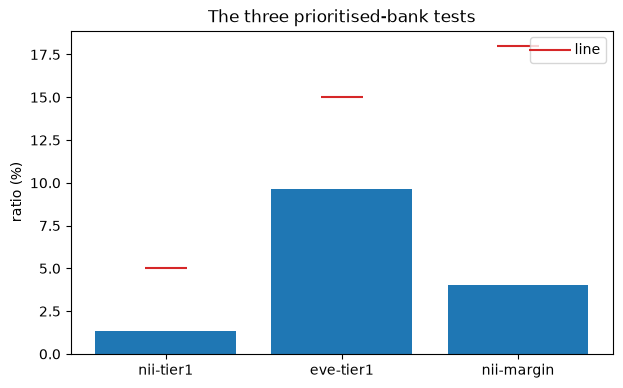

In [11]:
# Apply the three prioritised-bank tests to the recomputed measures
th = out["thresholds"]
pb = eve_nii.prioritised_bank(a2.delta_nii, a1.delta_eve, th["tier1"], th["net_interest_and_indexation_margin_12m"])
margin = th["net_interest_and_indexation_margin_12m"]
print("Tier 1:", round(th["tier1"], 1))
print("12-month margin:", round(margin, 1))
for test in pb.tests:
    print(f"{test['id']:10s} measure {test['measure']:11,.1f} / {test['base']:11,.1f} = {test['ratio']:.4f}")
    print(f"    line {test['threshold']:.2f} | {NAME[test['breached']]}")
print("prioritised:", NAME[pb.prioritised])
fig, ax = plt.subplots(figsize=(7, 4.2))
names = [t["id"] for t in pb.tests]
ax.bar(names, [t["ratio"] * 100 for t in pb.tests], color="tab:blue")
ax.scatter(names, [t["threshold"] * 100 for t in pb.tests], color="tab:red", marker="_", s=900, label="line")
ax.set_ylabel("ratio (%)")
ax.set_title("The three prioritised-bank tests")
ax.legend()
plt.show()

All three bars sit well under their red lines: the delta NII is 1.34 percent of Tier 1 against a line of 5, the delta EVE 9.66 percent against 15, and the delta NII 4.03 percent of the 12-month margin against 18. The bank is not prioritised, and the closest to a line is the delta EVE, at about two thirds of the way. The test is strict, a ratio strictly above its line, so a bank at exactly 15 percent is not prioritised. The picture is one variant, the net short UF bank; the sixth step compares it with the others, one of which does cross a line.

### Step 8: the floors

The Annex floors the post-shock rates at 0 percent for the peso and at -2 percent for the UR (notebook 02 showed the rule). The document keeps, for each leg, measure and shock, the lowest post-shock rate before the floor, its band, and its distance to the floor in basis points; a distance of zero or less means the floor binds. The engine's `apply_floor` is called here without a floor to read the raw shocked rate. The next cell recomputes the distances for the 300 bp NII shocks and the six EVE shocks of both legs, lists the smallest ones, then checks all six variants for any floor that binds.

UR   delta NII  parallel down          band  1 |    20.48
CLP  delta EVE  short down             band  1 |    50.21
UR   delta EVE  short down             band  1 |    70.65
UR   delta EVE  parallel down          band  1 |   120.48
CLP  delta EVE  parallel down          band  3 |   148.68
CLP  delta NII  parallel down          band  3 |   148.68
floors that bind in each variant: {'short-uf': 0, 'long-uf': 0, 'cpi-surprise': 0, 'clp-steepener': 0, 'offset-on-off': 0, 'floors-active': 0}
smallest distance in each variant (bp): {'short-uf': 20.48, 'long-uf': 20.48, 'cpi-surprise': 20.48, 'clp-steepener': 20.48, 'offset-on-off': 20.48, 'floors-active': 20.48}


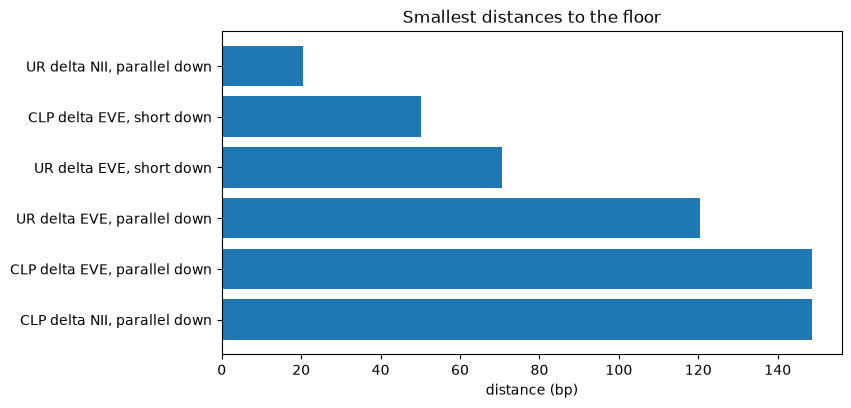

In [12]:
# Recompute the distance of every post-shock rate to its floor and list the smallest; look for binding floors
rows = []
for leg in ("CLP", "UR"):
    z = sizes[leg]
    for s in shocks.SHOCKS:
        raw = shocks.apply_floor(r0[leg], shocks.shock_curve(s, z.parallel_bp, z.short_bp, z.long_bp, MID), None)
        rows.append((leg, "delta-eve", s, int(np.argmin(raw)) + 1, (float(raw.min()) - floors[leg]) * 1e4))
    for s, bp in (("parallel-up", 300.0), ("parallel-down", -300.0)):
        raw = shocks.apply_floor(r0[leg], np.full(19, bp), None)[:6]
        rows.append((leg, "delta-nii", s, int(np.argmin(raw)) + 1, (float(raw.min()) - floors[leg]) * 1e4))
smallest = sorted(rows, key=lambda r: r[4])[:6]
for leg, measure, shock, band, distance in smallest:
    print(f"{leg:4s} {NAME[measure]:10s} {NAME[shock]:22s} band {band:2d} | {distance:8.2f}")
print("floors that bind in each variant:", {v: len(d["outputs"]["floors"]["effects"]) for v, d in variants.items()})
mins = {v: round(min(x["distance_bp"] for x in d["outputs"]["floors"]["distances"]), 2) for v, d in variants.items()}
print("smallest distance in each variant (bp):", mins)
labels = [f"{leg} {NAME[m]}, {NAME[s]}" for leg, m, s, _, _ in smallest]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(labels, [r[4] for r in smallest], color="tab:blue")
ax.set_xlabel("distance (bp)")
ax.set_title("Smallest distances to the floor")
ax.invert_yaxis()
plt.show()

The bars are the six smallest distances between a post-shock rate and its floor, in basis points, and none is zero, so no floor binds. The closest is the UR rate of the first band under the 300 bp fall in the NII measure, 20.48 bp from its floor of -2 percent; next come the peso short-down shock of the EVE at 50.21 bp, then 70.65 and 120.48 bp. The listing for the six variants confirms that no floor binds in any of them, including `floors-active`, which was built with 70 percent of the UF commercial loans floating to bring the floors into play and does not. With rates at today's levels the floor is a rule the engine implements and tests, not one that moves a number here.

### Step 9: the six variants

The last step puts the six variants side by side. For each variant the cell takes the per-leg deltas from the committed document, passes them to the engine's `annex1_delta_eve`, `annex1_delta_nii` and `prioritised_bank`, and prints the Annex measures, the ratios and whether the bank is prioritised. The figure draws the delta EVE over Tier 1 and the delta NII over Tier 1 against their lines.

                     ΔEVE  ΔEVE/T1      ΔNII  ΔNII/T1
short-uf           79,643   0.0966    11,067   0.0134
    prioritised: no | offset: on
long-uf            93,816   0.1138    11,213   0.0136
    prioritised: no | offset: on
cpi-surprise       93,816   0.1138    11,213   0.0136
    prioritised: no | offset: on
clp-steepener     140,645   0.1706     6,783   0.0082
    prioritised: yes | offset: on
offset-on-off      81,173   0.0985    11,016   0.0134
    prioritised: no | offset: compared
floors-active      60,764   0.0737     6,606   0.0080
    prioritised: no | offset: on


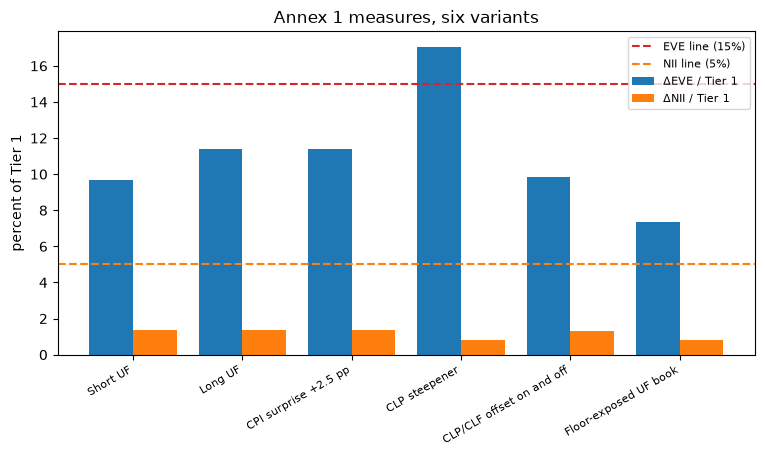

In [13]:
# For each variant: the Annex measures from the per-leg deltas with the engine, the ratios and the prioritised flag
summary = {}
print(f"{'':14s} {'ΔEVE':>10s} {'ΔEVE/T1':>8s} {'ΔNII':>9s} {'ΔNII/T1':>8s}")
for v, d in variants.items():
    o = d["outputs"]
    on = o["offset_rule"]["state"] != "off"
    rows_e, rows_n = o["eve"]["rows"], o["nii"]["rows"]
    pair_e = [np.array([r["pair"][k] for r in rows_e]) for k in ("delta_clp", "delta_ur")]
    pair_n = [np.array([r["pair"][k] for r in rows_n]) for k in ("delta_clp", "delta_ur")]
    m_eve = eve_nii.annex1_delta_eve(*pair_e, on)
    m_nii = eve_nii.annex1_delta_nii(*pair_n, o["indexation_charge"]["pn_ur"], on)
    t = o["thresholds"]
    margin = t["net_interest_and_indexation_margin_12m"]
    flag = eve_nii.prioritised_bank(m_nii.delta_nii, m_eve.delta_eve, t["tier1"], margin)
    ratio = {x["id"]: x["ratio"] for x in flag.tests}
    summary[v] = (ratio["eve-tier1"], ratio["nii-tier1"], flag.prioritised)
    eve_part = f"{m_eve.delta_eve:10,.0f} {ratio['eve-tier1']:8.4f}"
    print(f"{v:14s} {eve_part} {m_nii.delta_nii:9,.0f} {ratio['nii-tier1']:8.4f}")
    print(f"    prioritised: {NAME[flag.prioritised]} | offset: {NAME[o['offset_rule']['state']]}")
fig, ax = plt.subplots(figsize=(9, 4.2))
x = np.arange(len(ids))
ax.bar(x - 0.2, [summary[v][0] * 100 for v in ids], 0.4, label="ΔEVE / Tier 1")
ax.bar(x + 0.2, [summary[v][1] * 100 for v in ids], 0.4, label="ΔNII / Tier 1")
ax.axhline(15, color="tab:red", linestyle="--", label="EVE line (15%)")
ax.axhline(5, color="tab:orange", linestyle="--", label="NII line (5%)")
ax.set_xticks(x, [variants[v]["outputs"]["variant"]["label"][LANG] for v in ids], rotation=30, ha="right", fontsize=8)
ax.set_ylabel("percent of Tier 1")
ax.set_title("Annex 1 measures, six variants")
ax.legend(fontsize=8)
plt.show()

Only one bar crosses a red line: the peso steepener variant, a longer peso book, has a delta EVE of 17.06 percent of Tier 1 against the line of 15, and is the one prioritised bank of the six. The long-UF and CPI-surprise variants share their numbers, 11.38 percent, because the CPI scenario changes the effect of inflation and not the Annex measure, and they are the nearest of the others. The delta NII bars are all under the 5 percent line, between 0.80 and 1.36 percent. The picture is six synthetic variants of one synthetic bank: it shows which stress moves the Annex measures, not the risk of any real bank.

## Results

**Answer:** the Annex 1 puts the net short UF bank at a delta EVE of 79,643 CLP millions, 9.66 percent of Tier 1, decided by the parallel-up shock where both legs lose, and at a delta NII of 11,067, of which 6,182 is the indexation charge, 1.34 percent of Tier 1. The bank is not prioritised, because no ratio crosses its line, and no floor binds. Only the peso steepener variant crosses a line, a delta EVE of 17.06 percent of Tier 1, and is prioritised.

- **The two legs.** The peso leg has assets of 4,988,540 and liabilities of 3,917,062 (CLP millions), a net asset position of 1,071,478. The UR leg is tiny in its own unit, 65.89 and 71.94 million CLF, but at 40,877.73 pesos per UF its net position of -6.05 million CLF is -247,264 CLP millions, which is the -30 percent of Tier 1 the variant is built to have. That position, and not the size of the UF book, sets the charge.
- **The curves.** The peso curve has a Nelson-Siegel decay of 1 year and an error of 0.50 bp, the UF curve a decay of 2.5 years and 0.41 bp. At the shortest band the peso curve is at 0.04499 and the UF curve at 0.01205: the nominal curve sits about 3 points above the real one. The peso curve rests on three market yields and the policy rate, so its shortest point is a policy rate and not a market one; a validator should read that as an open choice, not a measurement.
- **Caps and multipliers.** The retail operational segment asks for 0.95 and 5.5 years and is cut to 0.90 and 5.0 years, the wholesale one asks for 0.60 and 4.5 years and is cut to 0.50 and 4.0 years, and the retail non-operational one asks for exactly its caps and is not cut. With a base prepayment of 0.05, the parallel-up, steepener and short-up shocks give 0.0400 and the other three 0.0600.
- **The delta EVE.** Both legs lose under the parallel-up shock (34,216.3 for the peso and 45,427.0 for the UR), which is the worst shock, so the pair is their sum, 79,643.4, and the offset does nothing. Where the legs go in opposite directions the offset acts: in the steepener the pair is 34,337.4 with it and 38,748.2 without, in the flattener 0.0 with it and 16,210.5 without. The offset changes the Annex measure only if it changes the worst shock, as the offset-on-off variant shows.
- **The delta NII and the charge.** The peso gains when rates rise (-7,059.4) and the UR loses (8,414.9): the pair with the offset is 4,885.3. The charge is 6,181.6, 0.5586 of the delta NII of 11,066.9: more than half of the NII measure is a function of the size of the net UF position, not of the shock. The charge is the same for a net short position of -247,264.2 and a net long one of 247,264.2, while a 2.5 point inflation surprise is a loss for the short bank and a gain for the long one: the standard charge is a one-sided add-on, the scenario is two-sided.
- **The tests.** The short-UF bank is at 0.0134 of Tier 1 for the delta NII (line 0.05), at 0.0966 for the delta EVE (line 0.15) and at 0.0403 of the 12-month margin (line 0.18): not prioritised. The long-UF variant, at 0.1138, is the nearest of the others to the EVE line.
- **The floors.** No floor binds in any of the six variants. The closest post-shock rate is the UR rate of the first band under a 300 bp fall, 20.48 bp from a floor of -2 percent; the next are 50.21 bp, 70.65 and 120.48 bp. The `floors-active` variant does not bring the floors into play: its name states the intent, not the result.
- **What the notebook does not show.** The dynamic NII and the Hull-White distributions of the two legs, the prices of the UF indexation itself (the real rate is on the curve, the inflation is in the charge), and any check of the Chilean figures against a second implementation: there is none to compare with (notebook 08).

## Summary

- The Chilean Annex treats the UF as one currency, the UR, with its own curve, its own shock sizes, a floor at -2 percent, and an indexation charge of 2.5 percent of the absolute net UF position; the engine implements each piece and never converts between currencies.
- The delta EVE takes the six shocks on each leg, pairs the legs with the 50 percent offset on the gain leg and takes the worst shock; the delta NII uses a single 300 bp shock, the same pairing and adds the charge once.
- The charge does not depend on the shock or on the sign of the position, so a net long UF bank, which gains from inflation, pays the same as a net short one.
- Three tests make a bank prioritised: the delta NII over 5 percent of Tier 1, the delta EVE over 15 percent, and the delta NII over 18 percent of the 12-month margin; one of the six variants crosses a line.
- No floor binds in any of the six variants; the closest post-shock rate is 20.48 bp from its floor, in the UR leg under a 300 bp fall.

**What to try next.** Choose the `long-uf` variant as the main one in the first cell and read how the pair of the first shock changes. Then continue with notebook 07, the state of the art.

## References

- CMF, Recopilacion Actualizada de Normas, chapter 21-13, Annex 1, Determinacion de la exposicion al riesgo de mercado en el libro de banca (Circular 2.270 of 2020 and 2.365 of 2025). https://www.cmfchile.cl/portal/principal/623/articles-29808_doc_pdf.pdf
- BCBS, Standards: Interest rate risk in the banking book, SRP31 (the shocks, the bands, the caps and the multipliers, repeated by the Annex). https://www.bis.org/basel_framework/chapter/SRP/31.htm
- CMF, Informe del Desempeno del Sistema Bancario y Cooperativas, August 2026, Cuadro N 1 (the aggregates of the synthetic bank). https://www.cmfchile.cl/portal/estadisticas/617/articles-113863_recurso_1.pdf
- Banco Central de Chile, Base de Datos Estadisticos, table F022 (secondary-market yields) and series F073.UFF.PRE.Z.D (the UF), terms of use. https://si3.bcentral.cl/estadisticas/Principal1/Web_Services/terminos_condiciones.html
- Nelson, C. R. and Siegel, A. F. (1987), Parsimonious modeling of yield curves, Journal of Business 60(4). https://doi.org/10.1086/296409
- Dossier 03 of the Contraste research (Chile), section F.2.